# From Text to Evidence: Word Frequencies in Python (2026)

**RTU DE0823 — Digital Discourse Studies** (formerly ETH713) · Technical Week 3 · Google Colab

In this practical demonstration, we will process two literary corpora: Lewis Carroll's *Alice's Adventures in Wonderland* (English) and Eduards Veidenbaums's poetry (Latvian). We will progress from text files to token frequencies, charts, and reproducible results.

**Learning outcomes:** open and inspect UTF-8 text files; explain corpus cleaning choices; compare whitespace and Unicode-aware tokenization; count tokens using a dictionary and `collections.Counter`; visualize and export frequencies; distinguish descriptive statistics from discourse interpretation.

**Run:** open in Google Colab, choose **Runtime → Run all**, or work through the cells in order. No Google Drive mount, API key, package installation, or manual file upload is required. The main analysis uses Python's standard library; plotting uses Matplotlib (available in standard Colab).

**Scope:** this notebook demonstrates word-form frequency analysis, not sentiment analysis, lemmatization, or discourse interpretation by itself.

## 1. Acquire two source texts

A Colab notebook runs in a temporary Linux environment, usually with `/content` as its working directory. Local files from a GitHub repository do **not** appear automatically when the notebook is opened in Colab.

We will explicitly download the two small, public source texts into a local `data/` folder. The source locations are declared once, to make the procedure visible and reproducible.

- [Alice — repository source](https://github.com/ValRCS/Digital_Discourse_ETH713_Fall_2020/blob/main/data/Alice_Wonderland.txt)
- [Veidenbaums — repository source](https://github.com/ValRCS/Digital_Discourse_ETH713_Fall_2020/blob/main/data/Veidenbaums.txt)

The URLs track the repository's `main` branch. If the source files change, results may also change.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_BASE = "https://raw.githubusercontent.com/ValRCS/Digital_Discourse_ETH713_Fall_2020/main/data"
source_names = ["Alice_Wonderland.txt", "Veidenbaums.txt"]

for filename in source_names:
    destination = DATA_DIR / filename
    # Download explicitly so a fresh Colab runtime has the needed file.
    urlretrieve(f"{RAW_BASE}/{filename}", destination)
    print(f"{destination}: {destination.stat().st_size:,} bytes")

data/Alice_Wonderland.txt: 174,693 bytes
data/Veidenbaums.txt: 13,914 bytes


### Inspect the downloaded files

`Path` works across Windows, macOS, and Linux. A relative path is resolved from the **current working directory**. In Colab, `Path.cwd()` normally returns `/content`.

In [2]:
print("Working directory:", Path.cwd())
for path in sorted(DATA_DIR.glob("*.txt")):
    print(f"{path.name:24} {path.stat().st_size:>9,} bytes")
assert all((DATA_DIR / name).is_file() for name in source_names)

Working directory: /content
Alice_Wonderland.txt       174,693 bytes
Veidenbaums.txt             13,914 bytes


### Read text using an explicit encoding

`read_text(encoding="utf-8-sig")` handles UTF-8 and also removes an optional UTF-8 byte-order mark. This is useful when working with mixed historical text exports. Python's default text encoding depends on the environment; it should not be assumed to be ASCII or UTF-8 in every situation.

In [3]:
alice_raw = (DATA_DIR / "Alice_Wonderland.txt").read_text(encoding="utf-8-sig")
veiden_raw = (DATA_DIR / "Veidenbaums.txt").read_text(encoding="utf-8-sig")

print(f"Alice:       {len(alice_raw):,} characters")
print(f"Veidenbaums: {len(veiden_raw):,} characters")
print("\nAlice — beginning of the source (repr shows special characters):")
print(repr(alice_raw[:250]))

Alice:       164,409 characters
Veidenbaums: 12,875 characters

Alice — beginning of the source (repr shows special characters):
'The Project Gutenberg EBook of Alice’s Adventures in Wonderland, by Lewis Carroll\n\nThis eBook is for the use of anyone anywhere in the United States and most\nother parts of the world at no cost and with almost no restrictions\nwhatsoever.  You may cop'


**Discussion:** Which part of the Alice source is part of the literary work, and which part is Project Gutenberg publication metadata? Why might that distinction change a frequency table?

## 2. Corpus boundaries and cleaning

First inspect, then clean. We should not erase information without understanding why. Keep the original text in `alice_raw` and construct a **new** variable `alice_text` for the analytical corpus.

This specific Project Gutenberg edition includes front matter and a long legal footer. Instead of guessing how many blank lines occur, identify the actual start of Chapter I and the final `THE END` line. These are **edition-specific markers**, not a universal Gutenberg parser.

In [4]:
chapter_marker = "\nCHAPTER I.\nDown the Rabbit-Hole"
end_marker = "\nTHE END"

start_index = alice_raw.find(chapter_marker)
end_index = alice_raw.find(end_marker, start_index + len(chapter_marker))

print("Chapter I marker index:", start_index)
print("Final THE END index:", end_index)

if start_index < 0 or end_index < 0 or end_index <= start_index:
    raise ValueError("Expected Alice corpus markers were not found; inspect the source edition.")

alice_text = alice_raw[start_index + 1:end_index].strip()
print(f"Source: {len(alice_raw):,} characters → corpus: {len(alice_text):,} characters")
print("Corpus start:", repr(alice_text[:110]))
print("Corpus end:", repr(alice_text[-110:]))

Chapter I marker index: 1435
Final THE END index: 145444
Source: 164,409 characters → corpus: 144,007 characters
Corpus start: 'CHAPTER I.\nDown the Rabbit-Hole\n\n\nAlice was beginning to get very tired of sitting by her sister on the\nbank, '
Corpus end: 'rows, and find a pleasure in all\ntheir simple joys, remembering her own child-life, and the happy summer\ndays.'


### Why not remove all blank lines?

Blank lines can encode paragraph, verse, or document boundaries. For a word-frequency exercise, `str.split()` and our tokenizer already treat whitespace as a separator; deleting line breaks first is unnecessary and can remove useful structure.

We can still inspect the number of non-empty lines without changing the text.

In [5]:
alice_lines = alice_text.splitlines() # we get all text lines indicated by newline \n symbol at end of each line, some lines might only have that \n symbol
# we can use list comprehension to get non empty alice lines
non_empty_alice_lines = [line for line in alice_lines if line.strip()]
print(f"Alice lines: {len(alice_lines):,}; non-empty lines: {len(non_empty_alice_lines):,}")
print("\nFirst five non-empty lines:")
for line in non_empty_alice_lines[:5]:
    print(line)

Alice lines: 3,349; non-empty lines: 2,476

First five non-empty lines:
CHAPTER I.
Down the Rabbit-Hole
Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into
the book her sister was reading, but it had no pictures or


In [7]:
# we could have used a loop instead of list comprehension to get clean lines
non_empty_alice_lines = []
for line in alice_lines:
    if line.strip(): # strip returns a new string without newlines, tabs, spaces, basically any whitespace from beginning and end
        non_empty_alice_lines.append(line)
# how many?
print(f"Alice lines: {len(alice_lines):,}; non-empty lines: {len(non_empty_alice_lines):,}")

Alice lines: 3,349; non-empty lines: 2,476


### Latvian source: poem titles as structural metadata

In this particular `Veidenbaums.txt` file, poem headings are marked with a trailing `***` and often repeat the opening words of a poem. We choose to remove **only those marked heading lines** from the counting corpus. This is a documented editorial choice: other projects might instead preserve titles as separate fields.

We retain the original `veiden_raw` and keep a list of titles for later examination.

In [8]:
veiden_lines = veiden_raw.splitlines()
poem_titles = [line.rsplit("***", 1)[0].strip()
               for line in veiden_lines if line.rstrip().endswith("***")]
veiden_body_lines = [line for line in veiden_lines
                     if not line.rstrip().endswith("***")]
veiden_text = "\n".join(veiden_body_lines).strip()

print(f"Marked poem titles: {len(poem_titles)}")
print("First three titles:", poem_titles[:3])
print(f"Veidenbaums: {len(veiden_raw):,} → {len(veiden_text):,} characters")
print("Corpus beginning:", repr(veiden_text[:125]))

assert poem_titles, "No poem titles found: the source format may have changed."
assert "Pēc ideāliem" in veiden_text

Marked poem titles: 26
First three titles: ['Pēc ideāliem cenšas lielie gari', 'Virs zemes nav taisnības', 'Ar šīs zemes varenajiem']
Veidenbaums: 12,875 → 12,117 characters
Corpus beginning: 'Pēc ideāliem cenšas lielie gari,\n\nBet dzīvē ieņemt vietu pirmie\n\nTie neiespēj, tos nomāc maizes kari,\n\nTos nomāc aizspriedumi'


**Check:** What is lost when the titles are excluded? If the research question concerns titling conventions or repeated themes, should the titles be part of the corpus?

## 3. Tokenization: from strings to word lists

A *token* is a unit extracted from text. The simplest approximation is to split on whitespace. That is convenient, but punctuation remains attached to words.

In [9]:
example = "“Alice’s” well-known story — dzīvē, taisnības! 2026"
print("Original:", example)
print("Whitespace splitting:", example.split())

Original: “Alice’s” well-known story — dzīvē, taisnības! 2026
Whitespace splitting: ['“Alice’s”', 'well-known', 'story', '—', 'dzīvē,', 'taisnības!', '2026']


Python regular expressions can describe more specific token boundaries.

The pattern below selects sequences of **Unicode letters**, optionally joined by an internal apostrophe or hyphen. This preserves Latvian letters, including `ā`, `ē`, `ī`, `ū`, `š`, `ž`, and `ķ`. Numbers and underscores are not counted as word tokens.

This is one defensible operational definition of a word, **not** a universal linguistic tokenizer: contractions, compounds, abbreviations, and historical orthography still require judgment.

In [10]:
import re # also standard library for working with regular expressions
import unicodedata #part of standard Python library for working with Unicode data

WORD_PATTERN = r"[^\W\d_]+(?:[’'-][^\W\d_]+)*"

def tokenize_words(text):
    """Return lowercased, NFC-normalized word-form tokens (Unicode-aware)."""
    normalized = unicodedata.normalize("NFC", text).casefold()
    return re.findall(WORD_PATTERN, normalized)

print("Unicode-aware tokens:", tokenize_words(example))
print("Uppercase test:", tokenize_words("DZĪVĒ Dzīvē dzīvē"))

Unicode-aware tokens: ['alice’s', 'well-known', 'story', 'dzīvē', 'taisnības']
Uppercase test: ['dzīvē', 'dzīvē', 'dzīvē']


### Compare whitespace and word tokenization

`str.split()` is useful for inspecting whitespace boundaries, but it is not a reliable final word count when punctuation is present. We use one canonical tokenization rule for both corpora.

In [11]:
alice_whitespace = alice_text.split()
alice_words = tokenize_words(alice_text)
veiden_words = tokenize_words(veiden_text)

print(f"Alice: {len(alice_whitespace):,} whitespace-delimited pieces")
print(f"Alice: {len(alice_words):,} normalized word tokens")
print(f"Veidenbaums: {len(veiden_words):,} normalized word tokens")
print("First Alice tokens:", alice_words[:15])
print("First Latvian tokens:", veiden_words[:15])

Alice: 26,439 whitespace-delimited pieces
Alice: 26,545 normalized word tokens
Veidenbaums: 1,868 normalized word tokens
First Alice tokens: ['chapter', 'i', 'down', 'the', 'rabbit-hole', 'alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by']
First Latvian tokens: ['pēc', 'ideāliem', 'cenšas', 'lielie', 'gari', 'bet', 'dzīvē', 'ieņemt', 'vietu', 'pirmie', 'tie', 'neiespēj', 'tos', 'nomāc', 'maizes']


**Normalization decisions:** `casefold()` merges uppercase and lowercase forms; this can obscure distinctions between names and ordinary nouns. The tokenizer preserves apostrophes and hyphens inside words but ignores standalone punctuation and numbers. Latvian inflected forms such as `sirds` and `sirdī` remain **different** word forms; they are not lemmatized.

## 4. Counting words with a dictionary

Before using a library, build a small frequency dictionary manually. A dictionary maps a key (the word form) to a value (its count). The expression `counts.get(word, 0)` returns zero if the key is not yet present.

In [12]:
manual_counts = {} # we start with a BLANK dictionary
for word in alice_words:
    # we add 1 to existing count of some key - key being a token such as say valdis
    # interesting case is if we have no count yet we get 0
    manual_counts[word] = manual_counts.get(word, 0) + 1

print("Unique word forms:", len(manual_counts))
print("Occurrences of 'alice':", manual_counts.get("alice", 0))
print("First five dictionary pairs:", list(manual_counts.items())[:5])

Unique word forms: 2663
Occurrences of 'alice': 386
First five dictionary pairs: [('chapter', 12), ('i', 410), ('down', 102), ('the', 1637), ('rabbit-hole', 4)]


In [13]:
# let's sort our manual_counts
sorted_manual_counts = sorted(manual_counts.items(), key=lambda x: x[1], reverse=True)
# top 5
print(sorted_manual_counts[:5])

[('the', 1637), ('and', 866), ('to', 725), ('a', 631), ('she', 541)]


In [14]:
# compare what happens if I did not supply key
different_sorted_manual_counts = sorted(manual_counts.items(), reverse=True)
print(different_sorted_manual_counts[:5])

[('zigzag', 1), ('zealand', 1), ('you’ve', 7), ('you’re', 23), ('you’ll', 6)]


### Use the standard library: `Counter`

Python already includes a specialized frequency dictionary, `collections.Counter`. Its `most_common(n)` method returns the most frequent tokens and their counts.

In [16]:
from collections import Counter # so Counter is a dictionary with extra benefits (methods)

alice_counts = Counter(alice_words)
veiden_counts = Counter(veiden_words)

assert manual_counts == alice_counts, "Manual counting and Counter disagree."
print("The manual dictionary and Counter agree.\n")
print("Top 15 English word forms:")
for word, count in alice_counts.most_common(15):
    print(f"{word:>15} : {count:>5}")

The manual dictionary and Counter agree.

Top 15 English word forms:
            the :  1637
            and :   866
             to :   725
              a :   631
            she :   541
             it :   530
             of :   511
           said :   462
              i :   410
          alice :   386
             in :   366
            you :   365
            was :   357
           that :   280
             as :   263


### Basic reproducibility checks

Counts must be internally consistent: the sum of individual token frequencies equals the length of the token list. `Counter` returns zero for a missing key (unlike a normal dictionary's bracket lookup).

In [17]:
assert sum(alice_counts.values()) == len(alice_words)
assert sum(veiden_counts.values()) == len(veiden_words)
assert alice_counts["alice"] > 0
assert veiden_counts["pēc"] > 0
assert alice_counts["this_word_is_not_in_the_corpus"] == 0

print("All counting checks passed.")
print("Alice total tokens:", len(alice_words))
print("Alice unique forms:", len(alice_counts))
print("Veidenbaums total tokens:", len(veiden_words))
print("Veidenbaums unique forms:", len(veiden_counts))

All counting checks passed.
Alice total tokens: 26545
Alice unique forms: 2663
Veidenbaums total tokens: 1868
Veidenbaums unique forms: 1067


## 5. Why cleaning decisions change results

A frequency table reflects *the corpus definition*. To make this visible, compare the count of several words before and after removing Project Gutenberg metadata.

We apply the **same tokenizer** to both versions; only the selected corpus boundaries change.

In [18]:
alice_raw_counts = Counter(tokenize_words(alice_raw))
print(f"{'word':>12} {'raw file':>12} {'literary text':>16}")
for word in ["alice", "gutenberg", "project", "chapter", "the"]:
    print(f"{word:>12} {alice_raw_counts[word]:>12} {alice_counts[word]:>16}")

assert alice_raw_counts["gutenberg"] > alice_counts["gutenberg"]

        word     raw file    literary text
       alice          386              386
   gutenberg           40                0
     project           88                0
     chapter           24               12
         the         1832             1637


Notice that Project Gutenberg vocabulary may dominate the *difference* between the two corpora, even though it is not part of the novel. Corpus preparation is therefore a methodological, not merely cosmetic, operation.

**Question:** Would it be appropriate to discard all words shorter than five characters? Such a rule also removes pronouns and other discourse-relevant words.

### Filtering by length (a demonstration, not stopword removal)

For a quick view of less common function words, try a minimum length. This is **not** a linguistically validated stopword filter. We preserve the unfiltered counters for the primary results.

In [19]:
MIN_LENGTH = 4
alice_long_counts = Counter(word for word in alice_words if len(word) >= MIN_LENGTH)
veiden_long_counts = Counter(word for word in veiden_words if len(word) >= MIN_LENGTH)

print("Alice, four or more characters:", alice_long_counts.most_common(12))
print("Veidenbaums, four or more characters:", veiden_long_counts.most_common(12))

Alice, four or more characters: [('said', 462), ('alice', 386), ('that', 280), ('with', 181), ('very', 144), ('what', 136), ('this', 134), ('they', 130), ('little', 128), ('down', 102), ('then', 94), ('about', 94)]
Veidenbaums, four or more characters: [('reiz', 10), ('viss', 9), ('līdz', 8), ('mums', 7), ('sauc', 6), ('gars', 6), ('projām', 6), ('laiks', 5), ('sirds', 5), ('tomēr', 5), ('likumīgi', 5), ('dzīves', 5)]


## 6. Visualize frequencies

A horizontal bar chart is easier to read than a crowded chart of dozens of vertically rotated word labels. We chart the 15 most frequent forms in each corpus. Matplotlib is preinstalled in Colab.

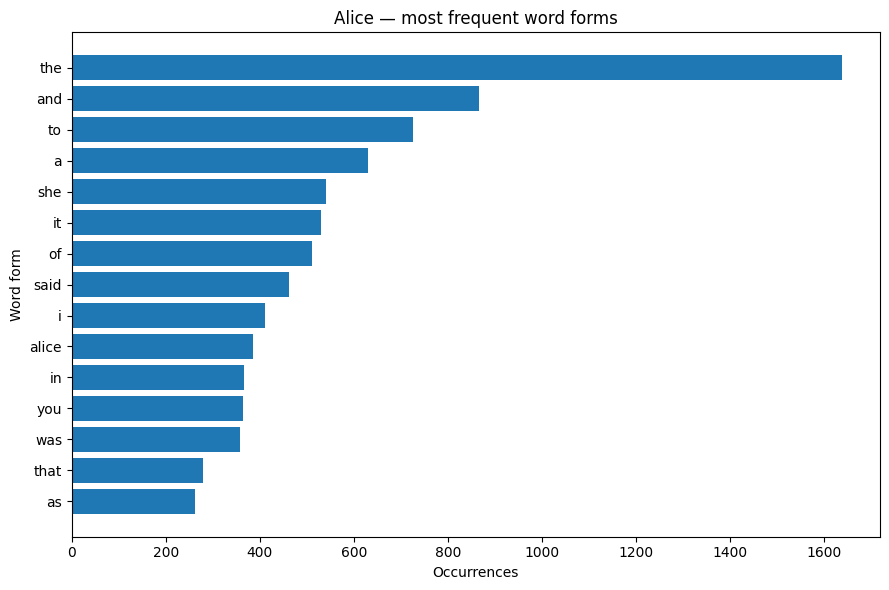

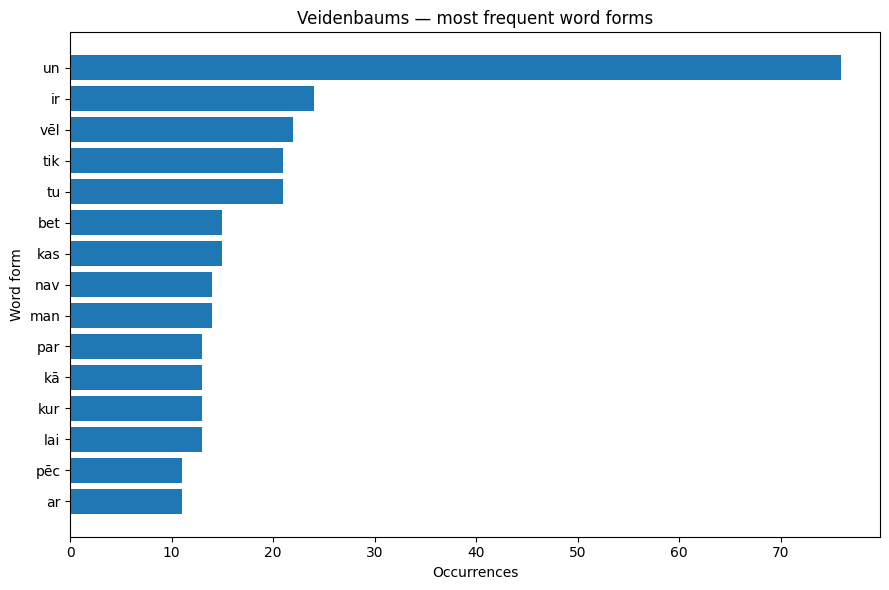

In [20]:
import matplotlib.pyplot as plt

def plot_top_words(counter, title, n=15):
    pairs = counter.most_common(n)[::-1]  # reverse for top-to-bottom reading
    labels = [word for word, count in pairs]
    counts = [count for word, count in pairs]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(labels, counts)
    ax.set_xlabel("Occurrences")
    ax.set_ylabel("Word form")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

plot_top_words(alice_counts, "Alice — most frequent word forms")
plot_top_words(veiden_counts, "Veidenbaums — most frequent word forms")

### Relative frequencies for corpora of unequal sizes

Raw counts depend on corpus size. For within- or between-corpus comparisons, frequencies *per 1,000 tokens* offer a basic normalization:

`frequency_per_1,000 = count / total_tokens × 1,000`

Be cautious about comparing the English and Latvian corpora directly: they differ in language, morphology, genre, and length.

In [21]:
def per_thousand(counter, word):
    total = sum(counter.values())
    return 1000 * counter[word] / total if total else 0.0

print("Alice: 'alice' per 1,000 tokens:", round(per_thousand(alice_counts, "alice"), 2))
print("Veidenbaums: 'pēc' per 1,000 tokens:", round(per_thousand(veiden_counts, "pēc"), 2))

Alice: 'alice' per 1,000 tokens: 14.54
Veidenbaums: 'pēc' per 1,000 tokens: 5.89


### Type–token ratio: a tempting but limited measure

The type–token ratio is the number of distinct word forms divided by the number of tokens. It depends strongly on text length; cross-language comparisons also reflect different inflectional systems. Treat it as a descriptive exercise, not a direct measure of an author's vocabulary richness.

In [22]:
for label, words, counts in [
    ("Alice", alice_words, alice_counts),
    ("Veidenbaums", veiden_words, veiden_counts),
]:
    ratio = len(counts) / len(words) if words else 0
    print(f"{label:12}: {len(words):>7,} tokens; {len(counts):>6,} forms; TTR = {ratio:.3f}")

Alice       :  26,545 tokens;  2,663 forms; TTR = 0.100
Veidenbaums :   1,868 tokens;  1,067 forms; TTR = 0.571


## 7. Export transparent, reproducible results

Save **unfiltered** token frequencies to separate UTF-8 TSV files. TSV (tab-separated values) is readable in Excel and other tools; `csv.writer` handles quoting and delimiters correctly. Keeping the original source and the processing rules is essential for reproducibility.

In [23]:
import csv # another standard library in Python

def export_tsv(counter, destination):
    with destination.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.writer(stream, delimiter="\t") # so using tab as separator
        writer.writerow(["word", "count"])
        writer.writerows(counter.most_common())
    return destination

alice_output = export_tsv(alice_counts, OUTPUT_DIR / "alice_word_frequencies.tsv")
veiden_output = export_tsv(veiden_counts, OUTPUT_DIR / "veidenbaums_word_frequencies.tsv")

for path in [alice_output, veiden_output]:
    print(path, f"({path.stat().st_size:,} bytes)")

outputs/alice_word_frequencies.tsv (28,039 bytes)
outputs/veidenbaums_word_frequencies.tsv (11,228 bytes)


### Verify the exported files

Reading the first rows back provides an inexpensive test of the export format and Unicode preservation.

In [24]:
with veiden_output.open("r", encoding="utf-8", newline="") as stream:
    reader = csv.reader(stream, delimiter="\t")
    first_rows = [next(reader) for _ in range(4)]

print("Latvian TSV sample:")
for row in first_rows:
    print(row)
assert first_rows[0] == ["word", "count"]

print("\nNotebook completed: both source texts processed and both TSV files exported.")

Latvian TSV sample:
['word', 'count']
['un', '76']
['ir', '24']
['vēl', '22']

Notebook completed: both source texts processed and both TSV files exported.


To download a TSV in **Google Colab**, you can run this optional snippet in a new code cell (not needed for **Runtime → Run all**):

```python
from google.colab import files
files.download("outputs/alice_word_frequencies.tsv")
files.download("outputs/veidenbaums_word_frequencies.tsv")
```

The files live on Colab's temporary runtime until you download or otherwise save them.

In [25]:
from google.colab import files # so this is Google Colab specific library
# naturally if you run this notebook locally on your computer you would have no need to download anything :)
files.download("outputs/alice_word_frequencies.tsv")
files.download("outputs/veidenbaums_word_frequencies.tsv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Interpret before making claims

Word frequencies answer **how often a form occurs**, not **what a statement means**. For discourse analysis, we need context: concordance lines, co-occurrences, speaker attribution, narrative roles, and potentially qualitative close reading.

**Discussion prompts**

1. Why might pronouns such as `she` and `I` be more important than their short length suggests?
2. Does the count of `queen` say anything about how power is represented in Alice?
3. What information is lost when Latvian forms are counted separately rather than lemmatized?
4. How could the original poem-title markers become useful metadata instead of discarded lines?

**Student exercise:** select a meaningful word from either corpus. Report its absolute frequency and frequency per 1,000 tokens, locate three occurrences in the source text, and explain why those examples are or are not evidence for a discourse-level interpretation.

## Optional extensions (not required for the live demonstration)

- **Sentence segmentation:** experiment with `re.split(r"[.!?]+", alice_text)`. Discuss abbreviations and quotations; this is only a crude approximation.
- **Concordances:** use `re.finditer` or string searches to print short context windows around selected words.
- **Stopwords:** construct a documented language-specific list, then compare filtered and unfiltered results. Do not equate word length with stopword status.
- **Lemmatization:** investigate suitable morphological tools for Latvian and English; their output would not be directly comparable to the surface-word frequencies above.
- **Google Drive:** mount it in a *separate* optional Colab exercise if persistent file storage is needed. The main notebook deliberately requires no account authorization.
- **Sourcing:** record the source file's revision and any editorial decisions if you use these statistics in a research paper.

**Technical conventions:** Python 3, Unicode NFC + `casefold()`, regular expressions on letter sequences, `Counter` for frequencies, Matplotlib for plots, and UTF-8 TSV for exports. No NLP model is claimed or required.